#VACUUM CLEANER

You have used a **Simple Reflex Agent** in this Vacuum Cleaner application.

### Agent used: Simple Reflex Agent

A **Simple Reflex Agent** makes decisions based only on the **current state/percept** of the environment. It does not remember previous states.

In your program:

| Current condition                           | Agent action |
| ------------------------------------------- | ------------ |
| Current room is Dirty                       | **SUCK**     |
| Room is Clean and other room needs cleaning | **MOVE**     |
| Both rooms are Clean                        | **STOP**     |

For example:

```text
Room A = Dirty
Room B = Dirty
Position = A
        ↓
Agent observes Room A
        ↓
Room A is Dirty
        ↓
Action = SUCK
        ↓
Room A becomes Clean
        ↓
Action = MOVE RIGHT
        ↓
Agent reaches Room B
        ↓
Room B is Dirty
        ↓
Action = SUCK
        ↓
Both rooms Clean
        ↓
Action = STOP
```

### PEAS Details:

> **Agent Type:** Simple Reflex Agent
> **Environment:** Two-room vacuum cleaner environment
> **Percepts:** Current location and cleanliness status of the room
> **Actions:** Suck, Move Left, Move Right, Stop
> **Goal:** Clean all dirty rooms with appropriate actions.

The Python program is an implementation of a **Simple Reflex Vacuum Cleaner Agent**.


In [ ]:
# Simple Reflex Vacuum Cleaner Agent
# C = Clean
# D = Dirty
# X = Obstacle
# A = Vacuum Cleaner

def display(grid, agent_pos):
    for i in range(len(grid)):
        for j in range(len(grid[0])):
            if (i, j) == agent_pos:
                print("A", end=" ")
            else:
                print(grid[i][j], end=" ")
        print()
    print()


def vacuum_agent(grid, start):
    rows = len(grid)
    cols = len(grid[0])

    position = start
    cleaned = 0
    visited = set()

    # Directions: Up, Right, Down, Left
    directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]

    print("\nInitial Environment:")
    display(grid, position)

    while True:

        # Current percept
        r, c = position

        # Rule 1: If current room is dirty -> Suck
        if grid[r][c] == 'D':
            print(f"Agent at ({r}, {c}) -> DIRTY -> Suck")
            grid[r][c] = 'C'
            cleaned += 1

            display(grid, position)

        else:
            # Mark current room as visited
            visited.add(position)

            moved = False

            # Rule 2: Look for an unvisited reachable room
            for dr, dc in directions:
                nr = r + dr
                nc = c + dc

                if (0 <= nr < rows and
                    0 <= nc < cols and
                    grid[nr][nc] != 'X' and
                    (nr, nc) not in visited):

                    print(f"Agent at ({r}, {c}) -> CLEAN -> Move to ({nr}, {nc})")

                    position = (nr, nc)
                    moved = True
                    break

            # Stop if no unvisited room is available
            if not moved:
                break

    print("\nFinal Environment:")
    display(grid, position)

    print("Cleaning completed!")
    print("Total rooms cleaned:", cleaned)


# ---------------- MAIN PROGRAM ----------------

rows = int(input("Enter number of rows: "))
cols = int(input("Enter number of columns: "))

grid = []

print("\nEnter room status:")
print("C = Clean")
print("D = Dirty")
print("X = Obstacle")
print("A = Starting position")

start = None

for i in range(rows):
    row = []

    for j in range(cols):
        value = input(f"Room ({i},{j}): ").upper()

        while value not in ['C', 'D', 'X', 'A']:
            print("Invalid input! Enter C, D, X or A.")
            value = input(f"Room ({i},{j}): ").upper()

        if value == 'A':
            start = (i, j)
            row.append('C')   # Starting room is treated as clean
        else:
            row.append(value)

    grid.append(row)

if start is None:
    print("No starting position 'A' provided!")
else:
    vacuum_agent(grid, start)

Enter number of rows: 4
Enter number of columns: 5

Enter room status:
C = Clean
D = Dirty
X = Obstacle
A = Starting position
Room (0,0): A
Room (0,1): D
Room (0,2): C
Room (0,3): X
Room (0,4): D
Room (1,0): C
Room (1,1): D
Room (1,2): X
Room (1,3): D
Room (1,4): D
Room (2,0): X
Room (2,1): C
Room (2,2): C
Room (2,3): D
Room (2,4): C
Room (3,0): C
Room (3,1): X
Room (3,2): D
Room (3,3): C
Room (3,4): D

Initial Environment:
A D C X D 
C D X D D 
X C C D C 
C X D C D 

Agent at (0, 0) -> CLEAN -> Move to (0, 1)
Agent at (0, 1) -> DIRTY -> Suck
C A C X D 
C D X D D 
X C C D C 
C X D C D 

Agent at (0, 1) -> CLEAN -> Move to (0, 2)

Final Environment:
C C A X D 
C D X D D 
X C C D C 
C X D C D 

Cleaning completed!
Total rooms cleaned: 1


In [ ]:
# MODEL-BASED REFLEX VACUUM CLEANER AGENT

from collections import deque


def display(grid, agent):
    for i in range(len(grid)):
        for j in range(len(grid[0])):
            if (i, j) == agent:
                print("A", end=" ")
            else:
                print(grid[i][j], end=" ")
        print()
    print()


def find_nearest_dirty(grid, start, known_clean):

    rows = len(grid)
    cols = len(grid[0])

    queue = deque([start])
    parent = {start: None}

    directions = [(0, 1), (1, 0), (0, -1), (-1, 0)]

    while queue:

        current = queue.popleft()

        if grid[current[0]][current[1]] == 'D':
            path = []

            while current is not None:
                path.append(current)
                current = parent[current]

            return path[::-1]

        r, c = current

        for dr, dc in directions:

            nr = r + dr
            nc = c + dc
            next_pos = (nr, nc)

            if (0 <= nr < rows and
                0 <= nc < cols and
                grid[nr][nc] != 'X' and
                next_pos not in parent):

                parent[next_pos] = current
                queue.append(next_pos)

    return None


def model_based_agent(grid, start):

    agent = start
    cleaned = 0

    # Internal model of the environment
    model = {}

    print("\n--- MODEL-BASED REFLEX AGENT ---")
    display(grid, agent)

    while True:

        r, c = agent

        # Sense current room
        current_state = grid[r][c]

        # Update internal model
        model[agent] = current_state

        # Rule 1: Dirty -> Suck
        if current_state == 'D':

            print(f"At {agent}: DIRTY")
            print("Action: SUCK")

            grid[r][c] = 'C'
            model[agent] = 'C'
            cleaned += 1

            continue

        # Find nearest dirty room
        path = find_nearest_dirty(grid, agent, model)

        # No dirty room remaining
        if path is None:
            break

        # Move toward nearest dirty room
        if len(path) > 1:

            next_position = path[1]

            print(
                f"At {agent}: CLEAN "
                f"-> Moving to {next_position}"
            )

            agent = next_position

        else:
            break

    print("\nFinal Environment:")
    display(grid, agent)

    print("Rooms cleaned:", cleaned)
    print("Rooms remembered by agent:", len(model))


# ---------------- INPUT ----------------

rows = int(input("Enter rows: "))
cols = int(input("Enter columns: "))

grid = []
start = None

print("\nEnter:")
print("C = Clean")
print("D = Dirty")
print("X = Obstacle")
print("A = Agent")

for i in range(rows):

    row = []

    for j in range(cols):

        value = input(f"Room ({i},{j}): ").upper()

        while value not in ['C', 'D', 'X', 'A']:
            print("Invalid input!")
            value = input(f"Room ({i},{j}): ").upper()

        if value == 'A':
            start = (i, j)
            row.append('C')
        else:
            row.append(value)

    grid.append(row)


if start is not None:
    model_based_agent(grid, start)
else:
    print("Please specify starting position A.")

Enter rows: 3
Enter columns: 4

Enter:
C = Clean
D = Dirty
X = Obstacle
A = Agent
Room (0,0): c
Room (0,1): D
Room (0,2): X
Room (0,3): C
Room (1,0): A
Room (1,1): D
Room (1,2): C
Room (1,3): C
Room (2,0): A
Room (2,1): C
Room (2,2): D
Room (2,3): C

--- MODEL-BASED REFLEX AGENT ---
C D X C 
C D C C 
A C D C 

At (2, 0): CLEAN -> Moving to (2, 1)
At (2, 1): CLEAN -> Moving to (2, 2)
At (2, 2): DIRTY
Action: SUCK
At (2, 2): CLEAN -> Moving to (2, 1)
At (2, 1): CLEAN -> Moving to (1, 1)
At (1, 1): DIRTY
Action: SUCK
At (1, 1): CLEAN -> Moving to (0, 1)
At (0, 1): DIRTY
Action: SUCK

Final Environment:
C A X C 
C C C C 
C C C C 

Rooms cleaned: 3
Rooms remembered by agent: 5


Enter number of rows (e.g. 8): 4
Enter number of columns (e.g. 10): 3
Obstacle density 0-1 (e.g. 0.25): 0.55
Dirty density 0-1 (e.g. 0.35): 0.25

Generated a 4x3 environment with 0 dirty rooms and obstacle density 55%.
Agent starting position: (3, 1)



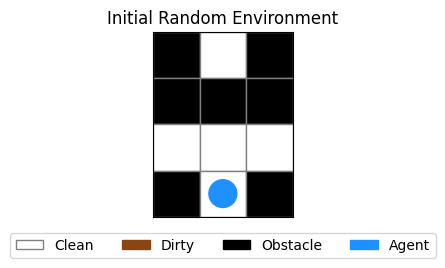


SIMPLE REFLEX AGENT — Initial Environment
X C X 
X X X 
C C C 
X A X 


SIMPLE REFLEX AGENT — Final Environment
X C X 
X X X 
C C C 
X A X 

Cleaned: 0 | Moves: 0 | Bumps: 1 | Steps used: 1

MODEL-BASED REFLEX AGENT — Initial Environment
X C X 
X X X 
C C C 
X A X 


MODEL-BASED REFLEX AGENT — Final Environment
X C X 
X X X 
C C C 
X A X 

Cleaned: 0 | Moves: 0 | Bumps: 0 | Rooms remembered: 1


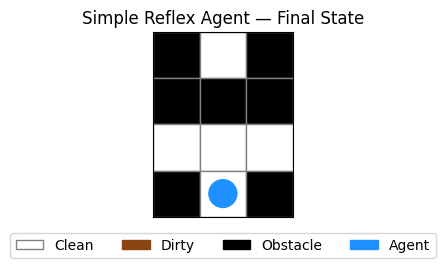

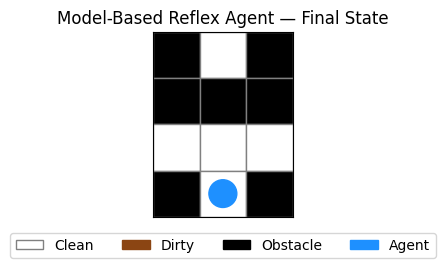

Metric                   Simple Reflex     Model-Based       
Total dirty rooms        0                 0                 
Rooms cleaned            0                 0                 
Moves made               0                 0                 
Bumps into obstacles     1                 0                 
Performance score        -5                0                 

Conclusion: The Model-Based Reflex Agent performed better because it remembers the map and uses BFS pathfinding to reach dirty rooms directly, instead of moving randomly like the Simple Reflex Agent.


In [1]:
# =========================================================
# VACUUM CLEANER AGENT — Randomized Large Grid Environment
# Comparing Simple Reflex Agent vs Model-Based Reflex Agent
# =========================================================
#
# PEAS Description
# -----------------
# Performance Measure : +10 per room cleaned, -1 per move, -5 per bump into obstacle
# Environment          : NxM grid of rooms, some Dirty(D), some Clean(C), some Obstacles(X)
# Actuators             : Suck, Move(Up/Down/Left/Right)
# Sensors               : Current room status, adjacent room status (model-based agent only)
#
# This version differs from a basic 2-room manual-input agent by:
#   1. Randomly generating a MUCH larger grid (configurable rows/cols)
#   2. Adding a higher density of obstacles
#   3. Implementing TWO agent types for comparison (Simple Reflex & Model-Based Reflex)
#   4. Scoring each agent with a numeric performance measure
#   5. Visualizing the environment with matplotlib (before & after)

import random
import copy
from collections import deque
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

random.seed()  # remove/change for reproducibility

# ---------------------------------------------------------
# 1. ENVIRONMENT GENERATION
# ---------------------------------------------------------
def generate_environment(rows, cols, obstacle_ratio=0.20, dirty_ratio=0.35):
    """Randomly generates a grid with Clean(C), Dirty(D) and Obstacle(X) rooms,
    plus a valid random starting position that is not an obstacle."""
    grid = []
    for i in range(rows):
        row = []
        for j in range(cols):
            r = random.random()
            if r < obstacle_ratio:
                row.append('X')
            elif r < obstacle_ratio + dirty_ratio:
                row.append('D')
            else:
                row.append('C')
        grid.append(row)

    # Pick a random valid (non-obstacle) starting position
    while True:
        sr, sc = random.randrange(rows), random.randrange(cols)
        if grid[sr][sc] != 'X':
            grid[sr][sc] = 'C'   # start room is guaranteed clean
            return grid, (sr, sc)


def count_dirty(grid):
    return sum(row.count('D') for row in grid)


def display(grid, agent_pos, title=""):
    if title:
        print(f"\n{title}")
    for i, row in enumerate(grid):
        line = ""
        for j, val in enumerate(row):
            line += ("A " if (i, j) == agent_pos else f"{val} ")
        print(line)
    print()


# ---------------------------------------------------------
# 2. PERFORMANCE MEASURE
# ---------------------------------------------------------
def performance_score(cleaned, moves, bumps):
    """Standard AI performance measure for vacuum agents:
       reward for cleaning, penalty for wasted moves/bumps."""
    return (cleaned * 10) - (moves * 1) - (bumps * 5)


# ---------------------------------------------------------
# 3. SIMPLE REFLEX AGENT
#    Decides only from CURRENT percept, no memory of the map.
#    Moves to a random valid neighbour when current room is clean.
# ---------------------------------------------------------
def simple_reflex_agent(grid, start, max_steps=500, verbose=True):
    grid = copy.deepcopy(grid)
    rows, cols = len(grid), len(grid[0])
    agent = start
    cleaned = moves = bumps = 0
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    if verbose:
        display(grid, agent, "SIMPLE REFLEX AGENT — Initial Environment")

    steps = 0
    while steps < max_steps:
        r, c = agent
        if grid[r][c] == 'D':
            grid[r][c] = 'C'
            cleaned += 1
            if verbose:
                print(f"Step {steps}: At {agent} -> DIRTY -> SUCK")
        else:
            dr, dc = random.choice(directions)
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] != 'X':
                agent = (nr, nc)
                moves += 1
            else:
                bumps += 1  # tried to move into a wall/obstacle
        steps += 1

        if count_dirty(grid) == 0:
            break

    if verbose:
        display(grid, agent, "SIMPLE REFLEX AGENT — Final Environment")
        print(f"Cleaned: {cleaned} | Moves: {moves} | Bumps: {bumps} | Steps used: {steps}")

    return grid, cleaned, moves, bumps, steps


# ---------------------------------------------------------
# 4. MODEL-BASED REFLEX AGENT
#    Maintains an internal MAP of the world and uses BFS to
#    plan the shortest path to the nearest known dirty room.
# ---------------------------------------------------------
def find_nearest_dirty(grid, start):
    rows, cols = len(grid), len(grid[0])
    visited = {start}
    queue = deque([(start, [start])])
    while queue:
        (r, c), path = queue.popleft()
        if grid[r][c] == 'D':
            return path
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < rows and 0 <= nc < cols
                    and grid[nr][nc] != 'X' and (nr, nc) not in visited):
                visited.add((nr, nc))
                queue.append(((nr, nc), path + [(nr, nc)]))
    return None


def model_based_agent(grid, start, verbose=True):
    grid = copy.deepcopy(grid)
    agent = start
    cleaned = moves = bumps = 0
    internal_map = {}

    if verbose:
        display(grid, agent, "MODEL-BASED REFLEX AGENT — Initial Environment")

    while True:
        r, c = agent
        internal_map[agent] = grid[r][c]

        if grid[r][c] == 'D':
            grid[r][c] = 'C'
            internal_map[agent] = 'C'
            cleaned += 1
            if verbose:
                print(f"At {agent}: DIRTY -> SUCK")
            continue

        path = find_nearest_dirty(grid, agent)
        if path is None or len(path) == 1:
            break  # no more reachable dirty rooms

        next_pos = path[1]
        if verbose:
            print(f"At {agent}: CLEAN -> Moving toward {next_pos} (nearest dirty room)")
        agent = next_pos
        moves += 1

    if verbose:
        display(grid, agent, "MODEL-BASED REFLEX AGENT — Final Environment")
        print(f"Cleaned: {cleaned} | Moves: {moves} | Bumps: {bumps} | "
              f"Rooms remembered: {len(internal_map)}")

    return grid, cleaned, moves, bumps


# ---------------------------------------------------------
# 5. VISUALIZATION
# ---------------------------------------------------------
def visualize(grid, agent_pos, title):
    rows, cols = len(grid), len(grid[0])
    color_map = {'C': 'white', 'D': 'saddlebrown', 'X': 'black'}

    fig, ax = plt.subplots(figsize=(cols * 0.6, rows * 0.6))
    for i in range(rows):
        for j in range(cols):
            color = color_map[grid[i][j]]
            ax.add_patch(plt.Rectangle((j, rows - i - 1), 1, 1,
                                        facecolor=color, edgecolor='gray'))
            if (i, j) == agent_pos:
                ax.add_patch(plt.Circle((j + 0.5, rows - i - 0.5), 0.3, color='dodgerblue'))

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

    legend = [mpatches.Patch(color='white', ec='gray', label='Clean'),
              mpatches.Patch(color='saddlebrown', label='Dirty'),
              mpatches.Patch(color='black', label='Obstacle'),
              mpatches.Patch(color='dodgerblue', label='Agent')]
    ax.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=4)
    plt.show()


# ---------------------------------------------------------
# 6. MAIN PROGRAM
# ---------------------------------------------------------
# Configure environment size — deliberately larger with more obstacles
try:
    ROWS = int(input("Enter number of rows (e.g. 8): ") or 8)
    COLS = int(input("Enter number of columns (e.g. 10): ") or 10)
    OBSTACLE_RATIO = float(input("Obstacle density 0-1 (e.g. 0.25): ") or 0.25)
    DIRTY_RATIO = float(input("Dirty density 0-1 (e.g. 0.35): ") or 0.35)
except ValueError:
    ROWS, COLS, OBSTACLE_RATIO, DIRTY_RATIO = 8, 10, 0.25, 0.35

base_grid, start_pos = generate_environment(ROWS, COLS, OBSTACLE_RATIO, DIRTY_RATIO)
total_dirty = count_dirty(base_grid)

print(f"\nGenerated a {ROWS}x{COLS} environment with {total_dirty} dirty rooms "
      f"and obstacle density {OBSTACLE_RATIO*100:.0f}%.")
print(f"Agent starting position: {start_pos}\n")

visualize(base_grid, start_pos, "Initial Random Environment")

# Run SIMPLE REFLEX AGENT
sr_grid, sr_clean, sr_moves, sr_bumps, sr_steps = simple_reflex_agent(
    base_grid, start_pos, max_steps=rows_max_steps if (rows_max_steps := ROWS*COLS*10) else 500, verbose=True
)
sr_score = performance_score(sr_clean, sr_moves, sr_bumps)

# Run MODEL-BASED REFLEX AGENT
mb_grid, mb_clean, mb_moves, mb_bumps = model_based_agent(base_grid, start_pos, verbose=True)
mb_score = performance_score(mb_clean, mb_moves, mb_bumps)

visualize(sr_grid, start_pos, "Simple Reflex Agent — Final State")
visualize(mb_grid, start_pos, "Model-Based Reflex Agent — Final State")

# ---------------------------------------------------------
# 7. PERFORMANCE COMPARISON REPORT
# ---------------------------------------------------------
print("=" * 60)
print(f"{'Metric':<25}{'Simple Reflex':<18}{'Model-Based':<18}")
print("=" * 60)
print(f"{'Total dirty rooms':<25}{total_dirty:<18}{total_dirty:<18}")
print(f"{'Rooms cleaned':<25}{sr_clean:<18}{mb_clean:<18}")
print(f"{'Moves made':<25}{sr_moves:<18}{mb_moves:<18}")
print(f"{'Bumps into obstacles':<25}{sr_bumps:<18}{mb_bumps:<18}")
print(f"{'Performance score':<25}{sr_score:<18}{mb_score:<18}")
print("=" * 60)

if mb_score > sr_score:
    print("\nConclusion: The Model-Based Reflex Agent performed better because it "
          "remembers the map and uses BFS pathfinding to reach dirty rooms directly, "
          "instead of moving randomly like the Simple Reflex Agent.")
else:
    print("\nConclusion: Results were close, but the Model-Based agent is generally "
          "more efficient in larger/more obstacle-dense environments.")